# USEFUL FUNCTIONS

In [1]:
def image_visualization_function(datset):

    image_plotting_sample = dataset.shuffle(seed = 42)[:8]
    images = image_plotting_sample['image']
    true_labels = image_plotting_sample['label']
    
    plt.figure(figsize=(15, 6))
    for i, image in enumerate(images):
        plt.subplot(2, int(len(images)/2), i + 1)
        plt.imshow(image)
        plt.title(labels[true_labels[i]]) # adding title to the images for more informative plot
        plt.axis('off') #elimitating axis in plot for a cleaner view 

# SET UP

In [2]:
# import basic packages
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import PIL
import torch

In [3]:
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))


GPU Available: True
Device Name: NVIDIA GeForce MX250


# Import Garbage Classification Dataset

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\pedro\.cache\kagglehub\datasets\sumn2u\garbage-classification-v2\versions\12


In [5]:
from datasets import load_dataset
dataset = load_dataset(path + "/standardized_384", split="train")

labels = dataset.features["label"].names
print(f"Labels: {labels}")
print(f"Number of images: {dataset.num_rows}")

Resolving data files:   0%|          | 0/12259 [00:00<?, ?it/s]

Labels: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Number of images: 12259


In [6]:
#Nello's count observations function
def count_observations(dataset):
    labels = dataset.features["label"].names
    label_counts = {label: dataset["label"].count(labels.index(label)) for label in labels}
    label_counts = pd.DataFrame.from_dict(label_counts, orient="index", columns=["count"]).reset_index(names="label")
    return label_counts

In [7]:
# Split dataset into train and test
data_split = dataset.train_test_split(test_size=0.2, shuffle=True, seed=42, stratify_by_column="label")
train = data_split["train"]
test = data_split["test"]
print("Train Split:\n", count_observations(train))
print("\nTest Split:\n", count_observations(test))

Train Split:
         label  count
0     battery    605
1  biological    559
2   cardboard   1129
3     clothes   1513
4       glass   1389
5       metal    744
6       paper   1069
7     plastic   1278
8       shoes   1159
9       trash    362

Test Split:
         label  count
0     battery    151
1  biological    140
2   cardboard    282
3     clothes    379
4       glass    347
5       metal    186
6       paper    267
7     plastic    319
8       shoes    290
9       trash     91


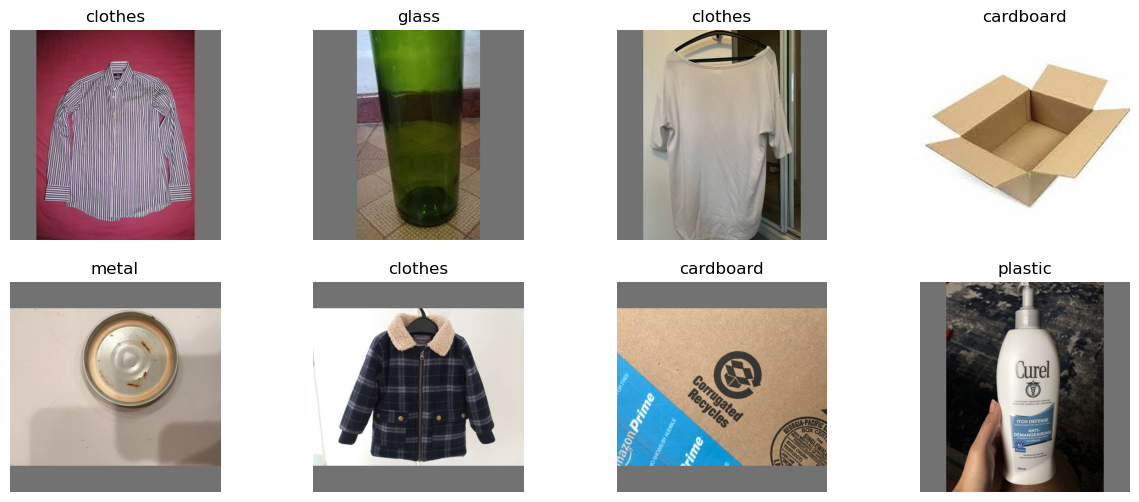

In [8]:
image_visualization_function(train) #function for image visualization, space optimization

# Image Embeddings

In [23]:
from transformers import CLIPImageProcessor, CLIPVisionModelWithProjection

image_processor = CLIPImageProcessor.from_pretrained("openai/clip-vit-base-patch32")

def preprocess_images(examples):
    images = examples["image"]
    inputs = image_processor(images, return_tensors="pt")
    examples["pixel_values"] = inputs["pixel_values"]
    return examples

train_processed_images = train.map(preprocess_images, batched = True, remove_columns =["image"])
test_processed_images = test.map(preprocess_images, batched = True, remove_columns =["image"])


In [26]:
## Calculating Image Embeddings
from torch.utils.data import DataLoader
from tqdm import tqdm

image_model = CLIPVisionModelWithProjection.from_pretrained("openai/clip-vit-base-patch32").to(device)

def image_embeddings_and_classes_lists(dataset_processed, embedding_model = image_model):
    
    dataset_processed.set_format("torch", columns = ["pixel_values"], output_all_columns = True)
    loader = DataLoader(dataset_processed, batch_size = 32, num_workers = 4)

    embeds, labels = [], []

    for batch in tqdm(loader):
        with torch.no_grad():
            inputs = batch["pixel_values"].to(device)
            outputs = embedding_model(inputs)
        image_embeds = outputs.image_embeds
        image_embeds = image_embeds / image_embeds.norm(dim=-1, keepdim=True)
    
        embeds.append(image_embeds.cpu())
        labels.append(batch['label'])

    return torch.cat(embeds), torch.cat(labels)

training_embedings, training_labales = image_embeddings_and_classes_lists(train_processed_images)
test_embedings, test_labels = image_embeddings_and_classes_lists(test_processed_images)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0

# Text Embeddings 

In [39]:
from transformers import CLIPTextModelWithProjection, AutoTokenizer

text_model = CLIPTextModelWithProjection.from_pretrained("openai/clip-vit-base-patch32").to(device)
tokenizer = AutoTokenizer.from_pretrained("openai/clip-vit-base-patch32")

garbage_labels = ['battery', 'biological', 'cardboard', 'glass', 'metal', 'paper','trash']
prompts = [
    f'a photo of {label} garbage' if label in garbage_labels else f'a photo of {label}'
    for label in dataset.features['label'].names
]

tokens = tokenizer(prompts, padding = True, return_tensors = 'pt').to(device)
with torch.no_grad():
    outputs =  text_model(**tokens)

text_embeddings = outputs.text_embeds
text_embeddings = text_embeddings/text_embeddings.norm(dim=-1, keepdim=True)  


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CLIPTextModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_m

# CREATING NEURAL NETWORK

# Building the neural network

In [41]:
from torch import nn


device = 'cuda' if torch.cuda.is_available() else 'cpu'
class CLIPAdapterGarbageClassification(nn.Module):
    def __init__(self, reduction_parameter = 4 , alpha = 0.2, dim_in = 512):
        super().__init__()
        self.alpha = alpha
        self.MLP_linear_stack = nn.Sequential(
            nn.Linear(dim_in, dim_in // reduction_parameter, bias = True),
            nn.ReLU(),
            nn.Linear(dim_in // reduction_parameter, dim_in, bias = True),
            nn.ReLU()
        )
    def forward(self, x):
        logits = self.MLP_linear_stack(x)
        return self.alpha*logits + (1-self.alpha)*x

class CLIP_MLP_adapted(nn.Module):
    def __init__(self, text_embeddings, logit_scale = 100, reduction_parameter=4, alpha=0.2, dim_in=512):
        super().__init__()
        self.adapter = CLIPAdapterGarbageClassification(reduction_parameter, alpha, dim_in)
        self.register_buffer("text_embeddings", text_embeddings)  # frozen
        self.logit_scale = logit_scale

    def forward(self, image_embeds):
        adapted = self.adapter(image_embeds)
        adapted = adapted / adapted.norm(dim=-1, keepdim=True)
        logits = self.logit_scale * adapted @ self.text_embeddings.t()
        return logits
    
        

In [45]:
import random
from sklearn.metrics import accuracy_score

def sample_k_shot(embeddings, labels, k, seed):
    rng = random.Random(seed)
    idx_by_class = {c: (labels == c).nonzero(as_tuple=True)[0].tolist() for c in labels.unique().tolist()}
    chosen = []
    for c, idxs in idx_by_class.items():
        chosen.extend(rng.sample(idxs, min(k, len(idxs))))
    return embeddings[chosen], labels[chosen]

def train_adapter(support_embeds, support_labels, alpha, reduction_parameter, epochs=50, lr=1e-3):
    model = CLIP_MLP_adapted(
        text_embeddings,
        logit_scale=100.0,
        reduction_parameter=reduction_parameter,
        alpha=alpha
    ).to(device)
    optimizer = torch.optim.Adam(model.adapter.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    support_embeds, support_labels = support_embeds.to(device), support_labels.to(device)

    model.train()
    for _ in range(epochs):
        optimizer.zero_grad()
        logits = model(support_embeds)
        loss = criterion(logits, support_labels)
        loss.backward()
        optimizer.step()
    return model

def evaluate(model):
    model.eval()
    with torch.no_grad():
        logits = model(test_embedings.to(device))
        preds = logits.argmax(dim=-1).cpu()
    return accuracy_score(test_labels, preds)



In [46]:
k_values = [0, 1, 2, 4, 8, 16]
alpha_values = [0.1, 0.2, 0.5, 0.8]
reduction_values = [1, 2, 4, 8]
n_seeds = 5

results = []  # list of dicts, easier to turn into a DataFrame later

for k in k_values:
    if k == 0:
        # zero-shot doesn't depend on alpha/reduction_parameter, log it once
        results.append({
            "k": 0, "alpha": None, "reduction_parameter": None,
            "accuracy_mean": zero_shot_accuracy, "accuracy_std": 0.0
        })
        continue

    for alpha in alpha_values:
        for reduction_parameter in reduction_values:
            accs = []
            for seed in range(n_seeds):
                support_embeds, support_labels = sample_k_shot(training_embedings, training_labales, k, seed)
                model = train_adapter(support_embeds, support_labels, alpha, reduction_parameter)
                accs.append(evaluate(model))

            mean_acc, std_acc = np.mean(accs), np.std(accs)
            results.append({
                "k": k, "alpha": alpha, "reduction_parameter": reduction_parameter,
                "accuracy_mean": mean_acc, "accuracy_std": std_acc
            })
            print(f"k={k:2d} | alpha={alpha:.1f} | reduction={reduction_parameter:2d} "
                  f"-> acc={mean_acc:.4f} (+/-{std_acc:.4f})")

results_df = pd.DataFrame(results)

k= 1 | alpha=0.1 | reduction= 1 -> acc=0.7776 (+/-0.0538)
k= 1 | alpha=0.1 | reduction= 2 -> acc=0.7879 (+/-0.0499)
k= 1 | alpha=0.1 | reduction= 4 -> acc=0.7872 (+/-0.0454)
k= 1 | alpha=0.1 | reduction= 8 -> acc=0.7759 (+/-0.0414)
k= 1 | alpha=0.2 | reduction= 1 -> acc=0.7631 (+/-0.0514)
k= 1 | alpha=0.2 | reduction= 2 -> acc=0.7747 (+/-0.0538)
k= 1 | alpha=0.2 | reduction= 4 -> acc=0.7860 (+/-0.0490)
k= 1 | alpha=0.2 | reduction= 8 -> acc=0.7882 (+/-0.0412)
k= 1 | alpha=0.5 | reduction= 1 -> acc=0.7410 (+/-0.0535)
k= 1 | alpha=0.5 | reduction= 2 -> acc=0.7542 (+/-0.0581)
k= 1 | alpha=0.5 | reduction= 4 -> acc=0.7545 (+/-0.0553)
k= 1 | alpha=0.5 | reduction= 8 -> acc=0.7663 (+/-0.0486)
k= 1 | alpha=0.8 | reduction= 1 -> acc=0.6291 (+/-0.0667)
k= 1 | alpha=0.8 | reduction= 2 -> acc=0.6588 (+/-0.0707)
k= 1 | alpha=0.8 | reduction= 4 -> acc=0.6712 (+/-0.0551)
k= 1 | alpha=0.8 | reduction= 8 -> acc=0.6464 (+/-0.0623)
k= 2 | alpha=0.1 | reduction= 1 -> acc=0.7959 (+/-0.0247)
k= 2 | alpha=0

In [47]:
best_per_k = results_df.loc[results_df.groupby("k")["accuracy_mean"].idxmax()]
print(best_per_k)

best_overall = results_df.loc[results_df["accuracy_mean"].idxmax()]
print("\nBest overall config:\n", best_overall)

     k  alpha  reduction_parameter  accuracy_mean  accuracy_std
0    0    NaN                  NaN       0.765900      0.000000
8    1    0.2                  8.0       0.788173      0.041243
19   2    0.1                  4.0       0.803507      0.022268
35   4    0.1                  4.0       0.856281      0.006503
60   8    0.5                  8.0       0.876835      0.012670
70  16    0.2                  2.0       0.905057      0.006090

Best overall config:
 k                      16.000000
alpha                   0.200000
reduction_parameter     2.000000
accuracy_mean           0.905057
accuracy_std            0.006090
Name: 70, dtype: float64


In [48]:
# Zero-Shot accuracy as baseline (best model from Zero-Shot notebook)
zero_shot_accuracy = 0.7659

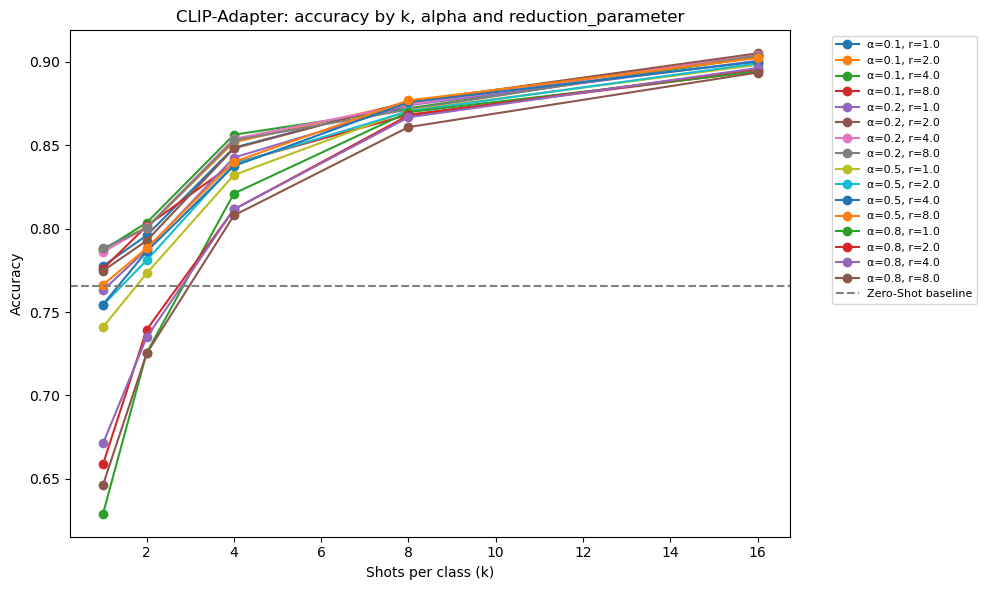

In [49]:
plt.figure(figsize=(10,6))
for (alpha, reduction), group in results_df[results_df["k"] > 0].groupby(["alpha", "reduction_parameter"]):
    plt.plot(group["k"], group["accuracy_mean"], marker='o', label=f"α={alpha}, r={reduction}")

plt.axhline(y=zero_shot_accuracy, color='gray', linestyle='--', label='Zero-Shot baseline')
plt.xlabel("Shots per class (k)")
plt.ylabel("Accuracy")
plt.title("CLIP-Adapter: accuracy by k, alpha and reduction_parameter")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

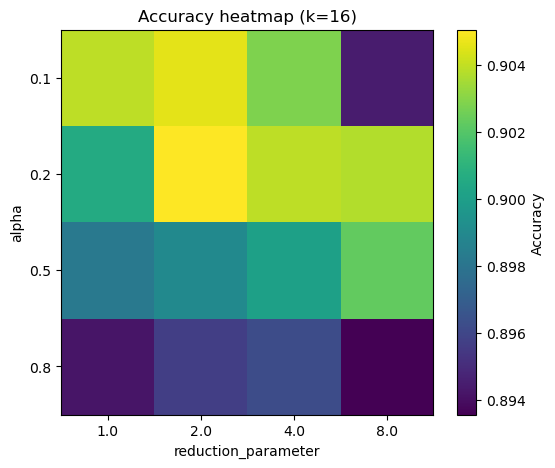

In [50]:
pivot = results_df[results_df["k"] == 16].pivot(index="alpha", columns="reduction_parameter", values="accuracy_mean")
plt.figure(figsize=(6,5))
plt.imshow(pivot, cmap="viridis", aspect="auto")
plt.colorbar(label="Accuracy")
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xlabel("reduction_parameter")
plt.ylabel("alpha")
plt.title("Accuracy heatmap (k=16)")
plt.show()